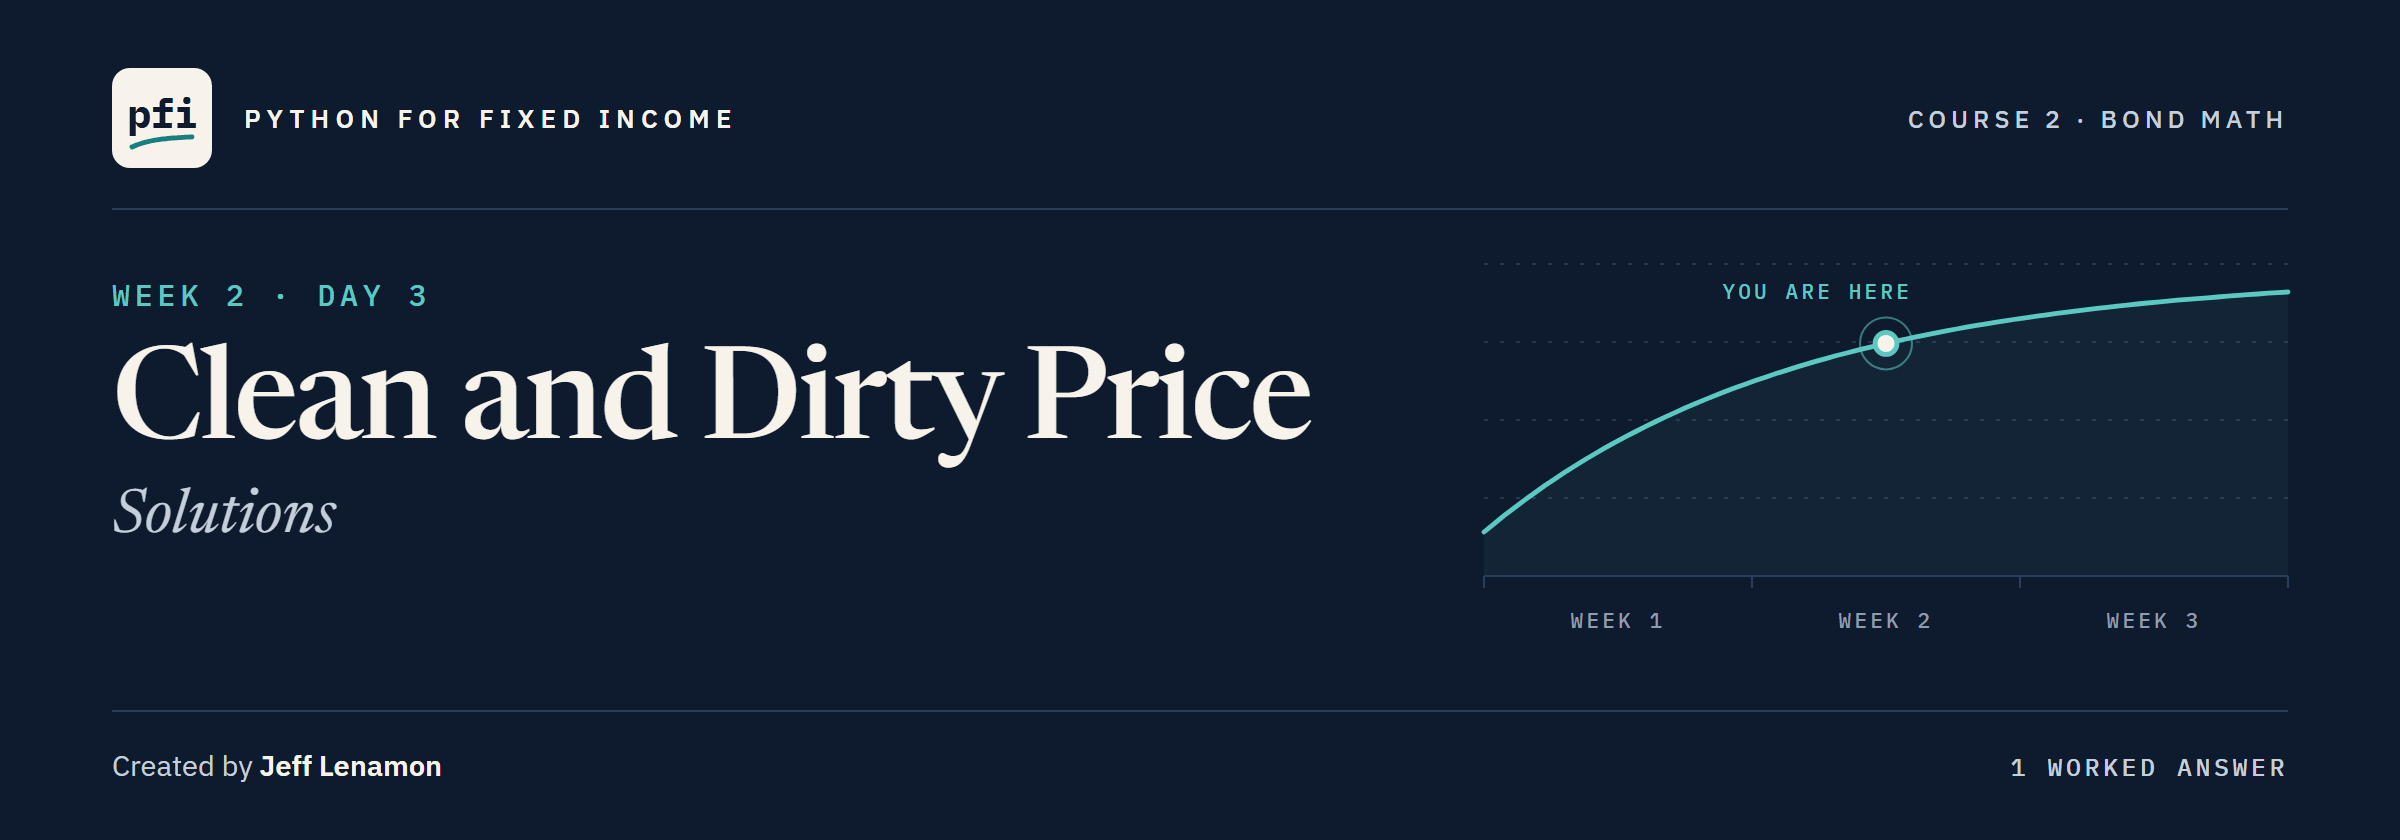

# Clean and Dirty Price: Solutions

Week 2, Day 3. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day3/08_clean_and_dirty_price_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports, `check`, and the bonds and trades.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 08 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(8, after=8)

Work folder pfi_course2_08_k4w7q2xr: 4 data files, the module as notebook 08 left it, 8 commits, tagged week1


In [2]:
import importlib
from datetime import date

import pandas as pd

import bondmath
settlement = date(2026, 11, 30)
reference = pd.read_csv('bondmath_excel_reference.csv')
print(len(reference), 'reference rows')

306 reference rows


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
exercise_bonds = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'maturity': [date(2030, 9, 30), date(2028, 9, 30), date(2032, 9, 30), date(2034, 9, 30)],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
})
# three trades: settlement, face in dollars, and the quoted clean price
exercise_trades = pd.DataFrame({
    'ticker': ['OSTV', 'OSMC', 'CLDB'],
    'settlement': [date(2027, 1, 15), date(2026, 12, 31), date(2027, 2, 26)],
    'face_dollars': [2_000_000, 1_500_000, 750_000],
    'clean_price': [99.40, 98.30, 98.10],
}).merge(exercise_bonds[['ticker', 'coupon_pct', 'maturity']], on='ticker')
exercise_trades

,ticker,settlement,face_dollars,clean_price,coupon_pct,maturity
0,OSTV,2027-01-15,2000000,99.4,5.625,2030-09-30
1,OSMC,2026-12-31,1500000,98.3,5.000,2032-09-30
2,CLDB,2027-02-26,750000,98.1,8.250,2034-09-30


### Exercise 1

In [5]:
terms = exercise_bonds.set_index('ticker')
ex1_calderby_clean = bondmath.price(settlement, terms.loc['CLDB', 'maturity'], 8.25, 8.6)
ex1_tarnwick_dirty = bondmath.dirty_price(settlement, terms.loc['TRNW', 'maturity'], 4.375, 4.3)
print(f'{ex1_calderby_clean:.6f} {ex1_tarnwick_dirty:.6f}')

98.015320 100.854875


In [6]:
check('Exercise 1 Calderby clean price', ex1_calderby_clean, 98.0153196112818)
check('Exercise 1 Tarnwick dirty price', ex1_tarnwick_dirty, 100.8548750077241)

Exercise 1 Calderby clean price: correct
Exercise 1 Tarnwick dirty price: correct


Excel agrees: the `week2` rows hold `PRICE` for all four, and Tarnwick's dirty price is its row's `PRICE` plus its accrued.

### Exercise 2

In [7]:
trades_in = list(zip(exercise_trades['settlement'], exercise_trades['maturity'],
                     exercise_trades['coupon_pct'], exercise_trades['clean_price']))
exercise_trades['accrued_per_100'] = [bondmath.accrued_interest(s, m, c)
                                     for s, m, c, p in trades_in]
exercise_trades['yield_pct'] = [bondmath.yield_to_maturity(s, m, c, p) for s, m, c, p in trades_in]
exercise_trades['invoice_dollars'] = (exercise_trades['face_dollars']
                                      * (exercise_trades['clean_price']
                                         + exercise_trades['accrued_per_100']) / 100)
exercise_trades[['ticker', 'accrued_per_100', 'yield_pct', 'invoice_dollars']]

,ticker,accrued_per_100,yield_pct,invoice_dollars
0,OSTV,1.640625,5.804191,2020812.50
1,OSMC,1.250000,5.345633,1493250.00
2,CLDB,3.345833,8.593363,760843.75


In [8]:
by_ticker = exercise_trades.set_index('ticker')
ex2_osmere_accrued = by_ticker.loc['OSMC', 'accrued_per_100']
ex2_calderby_yield = by_ticker.loc['CLDB', 'yield_pct']
ex2_total_invoice = exercise_trades['invoice_dollars'].sum()
check('Exercise 2 Osmere accrued', ex2_osmere_accrued, 1.25)
check('Exercise 2 Calderby yield', ex2_calderby_yield, 8.593362577678363)
check('Exercise 2 total invoice', ex2_total_invoice, 4274906.25)

Exercise 2 Osmere accrued: correct
Exercise 2 Calderby yield: correct
Exercise 2 total invoice: correct


Osmere settles on 31 December: rule 4 makes the 31st a 30th after a 30th start, so 90 of 180 days, half a coupon.
In Excel: `=YIELD(DATE(2027,2,26),DATE(2034,9,30),8.25/100,98.1,100,2,0)*100` returns 8.593362577645337.

### Exercise 3

In [9]:
%%writefile -a bondmath.py


def invoice_amount_dollars(par: float, clean_price: float, accrued_per_100: float) -> float:
    """The cash a trade settles for: principal plus accrued interest, in dollars.

    Units: par in dollars of face; clean_price and accrued_per_100 per 100 of face; the result in dollars.
    Convention: par x (clean price + accrued) / 100, the dirty price applied to the face.
    Excel: =par*(price+accrued)/100, with the accrued formula of notebook 07
    """
    # the dirty price per 100, applied to the face
    return par * (clean_price + accrued_per_100) / 100

Appending to bondmath.py


In [10]:
%%writefile -a test_bondmath.py


def test_invoice_amount_dollars_hand_cases():
    # 1,000,000 of face at 99.5 with 0.875 accrued: 995,000 principal plus 8,750 accrued
    assert bondmath.invoice_amount_dollars(1_000_000, 99.5, 0.875) == pytest.approx(1_003_750.0, abs=1e-6)
    # settled on a coupon date nothing has accrued, so the invoice is the principal
    assert bondmath.invoice_amount_dollars(500_000, 101.25, 0.0) == pytest.approx(506_250.0, abs=1e-6)

Appending to test_bondmath.py


In [11]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................                                                 [100%]
24 passed in 0.50s



In [12]:
# the file changed, so reload before calling the new function
importlib.reload(bondmath)
ostrevale = by_ticker.loc['OSTV']
ex3_ostrevale = bondmath.invoice_amount_dollars(ostrevale['face_dollars'],
                                                ostrevale['clean_price'],
                                                ostrevale['accrued_per_100'])
check('Exercise 3 Ostrevale invoice', ex3_ostrevale, 2020812.5)

Exercise 3 Ostrevale invoice: correct


In Excel: `=2000000*(99.4+100*5.625/100/2*COUPDAYBS(DATE(2027,1,15),DATE(2030,9,30),2,0)/COUPDAYS(DATE(2027,1,15),DATE(2030,9,30),2,0))/100` returns 2020812.5.

### Exercise 4: AI check

The bug: the function returns the sum of the discounted flows, the dirty price, where the docstring promises the clean price.
On a coupon date nothing has accrued and it would have passed, so a test on coupon-date rows alone misses it.
The fix takes off the accrued on the way out.

In [13]:
# written for this course in the style of an AI assistant's answer, now fixed
def assistant_price(settlement, maturity, coupon_pct, yield_pct, frequency=2, basis='30/360'):
    """Clean price per 100 of face on any settlement date, as Excel's PRICE."""
    dates = bondmath.coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = bondmath.coupon_period_days(settlement, maturity,
                                                                  frequency, basis)
    n, y, cf = len(dates) - 1, yield_pct / 100 / frequency, coupon_pct / frequency
    w = days_to_next / days_in_period
    if n == 1:
        # one coupon left: simple interest, as Excel does
        dirty = (100 + cf) / (1 + w * y)
    else:
        dirty = sum([(cf + (100 if k == n - 1 else 0)) / (1 + y) ** (w + k) for k in range(n)])
    # the fix: the docstring promises the clean price
    return dirty - bondmath.accrued_interest(settlement, maturity, coupon_pct, frequency, basis)

In [14]:
# the test file's reference rows and bond_inputs (notebook 07), read as the tests read them
from test_bondmath import REFERENCE, bond_inputs
for row in REFERENCE:
    result = assistant_price(*bond_inputs(row))
    # Excel's PRICE is the clean price, per 100 of face
    excel_price = float(row['price'])
    message = f"{row['case_id']}: {result:.6f}, PRICE {excel_price:.6f}"
    assert abs(result - excel_price) < 1e-6, message
print("Every row matches Excel's PRICE")

Every row matches Excel's PRICE


In [15]:
ex4_quorvane = assistant_price(settlement, date(2031, 9, 30), 5.25, 5.40)
ex4_calderby = assistant_price(settlement, date(2034, 9, 30), 8.25, 8.60)
check('Exercise 4 Quorvane clean price', ex4_quorvane, 99.36155142589136)
check('Exercise 4 Calderby clean price', ex4_calderby, 98.0153196112818)

Exercise 4 Quorvane clean price: correct
Exercise 4 Calderby clean price: correct


[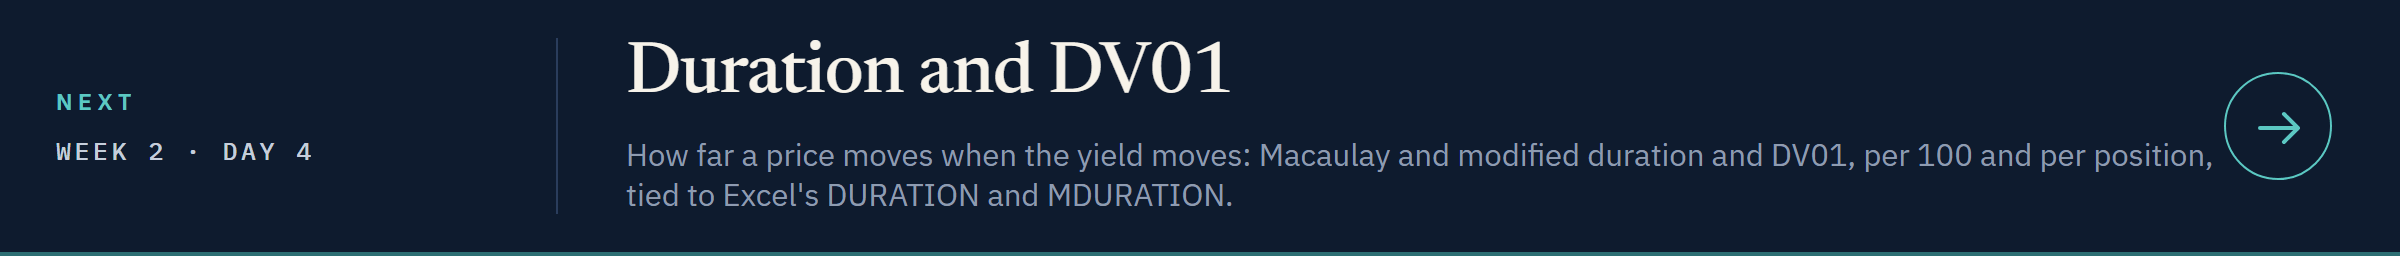](../day4/09_duration_and_dv01.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day4/09_duration_and_dv01.ipynb)